In [130]:
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from itertools import product
from tqdm import tqdm

rng = torch.Generator().manual_seed(57)

In [104]:
class SparseRNN(nn.Module):
    def __init__(self, n_vertices: int, n_in: int, n_out: int, n_ticks: int, edge_src: torch.Tensor, edge_dst: torch.Tensor, alpha: float = 1.0):
        super().__init__()
        self.n_vertices = n_vertices
        self.n_in = n_in
        self.n_out = n_out
        self.n_ticks = n_ticks
        self.edge_src = edge_src
        self.edge_dst = edge_dst
        self.edge_ws = nn.Parameter(torch.randn(len(edge_src), generator=rng))
        self.alpha = alpha

    def matvec(self, x: torch.Tensor):
        contrib = x.index_select(-1, self.edge_src) * self.edge_ws
        y = torch.zeros_like(x)
        y.index_add_(-1, self.edge_dst, contrib)
        return y

    def forward(self, inp: torch.Tensor):
        x = torch.zeros((*inp.shape[:-1], self.n_vertices))
        x[..., :self.n_in] = inp
        for _ in range(self.n_ticks):
            x = (1 - self.alpha) * x + self.alpha * torch.tanh(self.matvec(x))
        return x[..., -self.n_out:]

In [119]:
def train(model, inputs, labels, batches, lr):
    optimiser = torch.optim.Adam(model.parameters(), lr)
    for rows in batches:
        optimiser.zero_grad()
        logits = model(inputs[rows])
        loss = F.cross_entropy(logits, labels[rows])
        loss.backward()
        optimiser.step()

@torch.inference_mode()
def accuracy(model, inputs, labels):
    return (model(inputs).argmax(dim=-1) == labels).float().mean().item()

In [120]:
def build_dataset(fn, n_args):
    bits = torch.tensor(list(product((0, 1), repeat=n_args)))
    inputs = F.one_hot(bits, num_classes=2).flatten(1).float()
    labels = fn(bits).long()
    perm = torch.randperm(len(inputs), generator=rng)
    inputs, labels = inputs[perm], labels[perm]
    inputs_train, inputs_test = torch.split(inputs, len(inputs) * 3 // 4)
    labels_train, labels_test = torch.split(labels, len(labels) * 3 // 4)
    return inputs_train, labels_train, inputs_test, labels_test

def gen_batches(size, n_batches, batch_size):
    batches = []
    while len(batches) < n_batches:
        batches.extend(torch.randperm(size, generator=rng).split(batch_size))
    return batches[:n_batches]

In [180]:
def gen_graph_edge_indep(n_vertices, n_edges):
    return (
        torch.randint(0, n_vertices, (n_edges,), generator=rng),
        torch.randint(0, n_vertices, (n_edges,), generator=rng)
    )

def gen_graph_acyclic(n_vertices, n_edges):
    edge_src, edge_dst = [], []
    for _ in range(n_edges):
        u, v = torch.randint(0, n_vertices, (2,), generator=rng)
        if u > v:
            u, v = v, u
        edge_src.append(u)
        edge_dst.append(v)
    return torch.tensor(edge_src), torch.tensor(edge_dst)

In [181]:
def maj(x: torch.Tensor):
    return x.sum(dim=-1) * 2 > N_ARGS

def sum_4(x: torch.Tensor):
    return x.sum(dim=-1) == 4

def xor(x: torch.Tensor):
    return x.sum(dim=-1) % 2

#fn_confs = [(maj, 'maj'), (sum_4, 'sum_4'), (xor, 'xor')]
fn_confs = [(xor, 'xor')]

LR = 0.02
N_TICKS = 6
N_ARGS = 7
N_IN = 2 * N_ARGS
N_OUT = 2
BATCH_SIZE = 256
N_BATCHES = 1000
REPEAT = 1

rng = torch.Generator().manual_seed(57)
n_edges = 60

ns_vertices = [20, 30, 40, 60]
alphas = [0.25, 0.5, 0.75, 1.0]
train_accs, test_accs = [], []
for n_vertices, alpha in tqdm(product(ns_vertices, alphas), total=len(ns_vertices) * len(alphas)):
    train_accs.append([])
    test_accs.append([])
    for fn, fn_name in fn_confs:
        cur_train_accs, cur_test_accs = [], []
        for _ in range(REPEAT):
            #edge_src, edge_dst = gen_graph_edge_indep(n_vertices, n_edges)
            edge_src, edge_dst = gen_graph_acyclic(n_vertices, n_edges)
            model = SparseRNN(
                n_vertices=n_vertices,
                n_in=N_IN,
                n_out=N_OUT,
                n_ticks=N_TICKS,
                edge_src=edge_src,
                edge_dst=edge_dst,
                alpha=alpha
            )

            inputs_train, labels_train, inputs_test, labels_test = build_dataset(fn, N_ARGS)
            batches = gen_batches(len(inputs_train), N_BATCHES, BATCH_SIZE)
            train(model, inputs_train, labels_train, batches, LR)
            train_acc = accuracy(model, inputs_train, labels_train)
            test_acc = accuracy(model, inputs_test, labels_test)
            cur_train_accs.append(train_acc)
            cur_test_accs.append(test_acc)

        train_accs[-1].append(sum(cur_train_accs) / REPEAT)
        test_accs[-1].append(sum(cur_test_accs) / REPEAT)

    # print(f'Train accuracy for degree {n_edges / n_vertices}, alpha = {alpha}:', *train_accs[-1])
    # print(f'Test accuracy for degree {n_edges / n_vertices}, alpha = {alpha}:', *test_accs[-1])
    

100%|██████████| 16/16 [00:10<00:00,  1.48it/s]


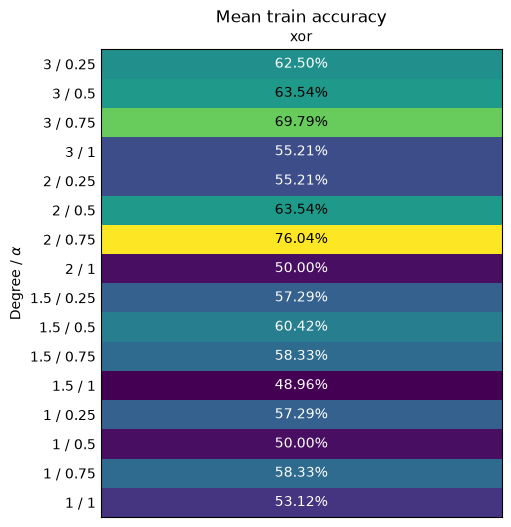

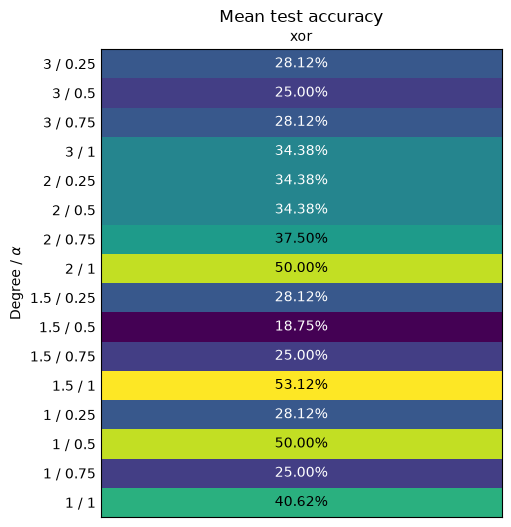

In [182]:
import numpy as np

def display_results(accs, title):
    scores = np.asarray(accs, dtype=float)
    lowest, highest = float(scores.min()), float(scores.max())
    row_labels = [f"{n_edges / vertices:g} / {leak:g}" for vertices, leak in product(ns_vertices, alphas)]

    fig, ax = plt.subplots(figsize=(5, 0.26 * len(scores) + 1), layout="constrained")
    ax.pcolormesh(scores)
    ax.set_xticks(0.5 + np.arange(len(fn_confs)), tuple(zip(*fn_confs))[1])
    ax.set_yticks(np.arange(len(scores)) + 0.5, row_labels)
    ax.xaxis.tick_top()
    ax.invert_yaxis()
    ax.tick_params(length=0)
    ax.set_ylabel("Degree / $\\alpha$")
    ax.set_title(title)

    for (row, col), score in np.ndenumerate(scores):
        color = "white" if score <= lowest + 0.5 * (highest - lowest) else "black"
        ax.text(col + 0.5, row + 0.5, f"{score:.2%}", ha="center", va="center", color=color)

display_results(train_accs, 'Mean train accuracy')
display_results(test_accs, 'Mean test accuracy')
plt.show()